# ExoDetect — classifying Kepler exoplanet candidates

Given a transit signal observed by the Kepler telescope, decide whether it is a
**confirmed planet**, a **candidate**, or a **false positive**.

Data: the cumulative *Kepler Objects of Interest* table from the NASA Exoplanet
Archive — 9,564 observations, 50 columns.

The work is split into five phases: load the data, explore it, clean it, train
the model, and explain what the model is actually using to decide.

## Phase 1 — Load and inspect

Before training anything I want to know what I have: how many rows, which
columns, where values are missing, and how the target column is distributed.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported.")

Libraries imported.


In [2]:
df = pd.read_csv("cumulative.csv")

print("Dataset loaded.")
print("Dataset shape:", df.shape)

Dataset loaded.
Dataset shape: (9564, 50)


`df.info()` tells me, column by column, how many non-null values there are and
what type they hold. A column with fewer than 9,564 non-null values has missing
data, which I will have to deal with in Phase 3.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Data columns (total 50 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   rowid              9564 non-null   int64  
 1   kepid              9564 non-null   int64  
 2   kepoi_name         9564 non-null   str    
 3   kepler_name        2294 non-null   str    
 4   koi_disposition    9564 non-null   str    
 5   koi_pdisposition   9564 non-null   str    
 6   koi_score          8054 non-null   float64
 7   koi_fpflag_nt      9564 non-null   int64  
 8   koi_fpflag_ss      9564 non-null   int64  
 9   koi_fpflag_co      9564 non-null   int64  
 10  koi_fpflag_ec      9564 non-null   int64  
 11  koi_period         9564 non-null   float64
 12  koi_period_err1    9110 non-null   float64
 13  koi_period_err2    9110 non-null   float64
 14  koi_time0bk        9564 non-null   float64
 15  koi_time0bk_err1   9110 non-null   float64
 16  koi_time0bk_err2   9110 non-null   

In [4]:
df.head()

   rowid     kepid kepoi_name   kepler_name koi_disposition koi_pdisposition  \
0      1  10797460  K00752.01  Kepler-227 b       CONFIRMED        CANDIDATE   
1      2  10797460  K00752.02  Kepler-227 c       CONFIRMED        CANDIDATE   
2      3  10811496  K00753.01           NaN  FALSE POSITIVE   FALSE POSITIVE   
3      4  10848459  K00754.01           NaN  FALSE POSITIVE   FALSE POSITIVE   
4      5  10854555  K00755.01  Kepler-664 b       CONFIRMED        CANDIDATE   

   koi_score  koi_fpflag_nt  koi_fpflag_ss  koi_fpflag_co  ...  \
0      1.000              0              0              0  ...   
1      0.969              0              0              0  ...   
2      0.000              0              1              0  ...   
3      0.000              0              1              0  ...   
4      1.000              0              0              0  ...   

   koi_steff_err2  koi_slogg  koi_slogg_err1  koi_slogg_err2  koi_srad  \
0           -81.0      4.467           0.064    

The column the model has to predict is `koi_disposition`. Let me see which
values it takes and how many examples there are of each.

In [5]:
print("Unique values in the target:")
print(df["koi_disposition"].unique())

print("\nCount per class:")
print(df["koi_disposition"].value_counts())

Unique values in the target:
<StringArray>
['CONFIRMED', 'FALSE POSITIVE', 'CANDIDATE']
Length: 3, dtype: str

Count per class:
koi_disposition
FALSE POSITIVE    5023
CONFIRMED         2293
CANDIDATE         2248
Name: count, dtype: int64


## Phase 2 — Exploratory analysis

Three questions: are the classes balanced? Which physical properties separate
the classes best? Are any columns redundant?

### Class imbalance

This matters because accuracy on its own can be misleading. If half the
observations are false positives, a model that always answers "FALSE POSITIVE"
is right half the time without having learned anything. I want that number as a
baseline to compare against.

FALSE POSITIVE   5023  (52.5%)
CONFIRMED        2293  (24.0%)
CANDIDATE        2248  (23.5%)


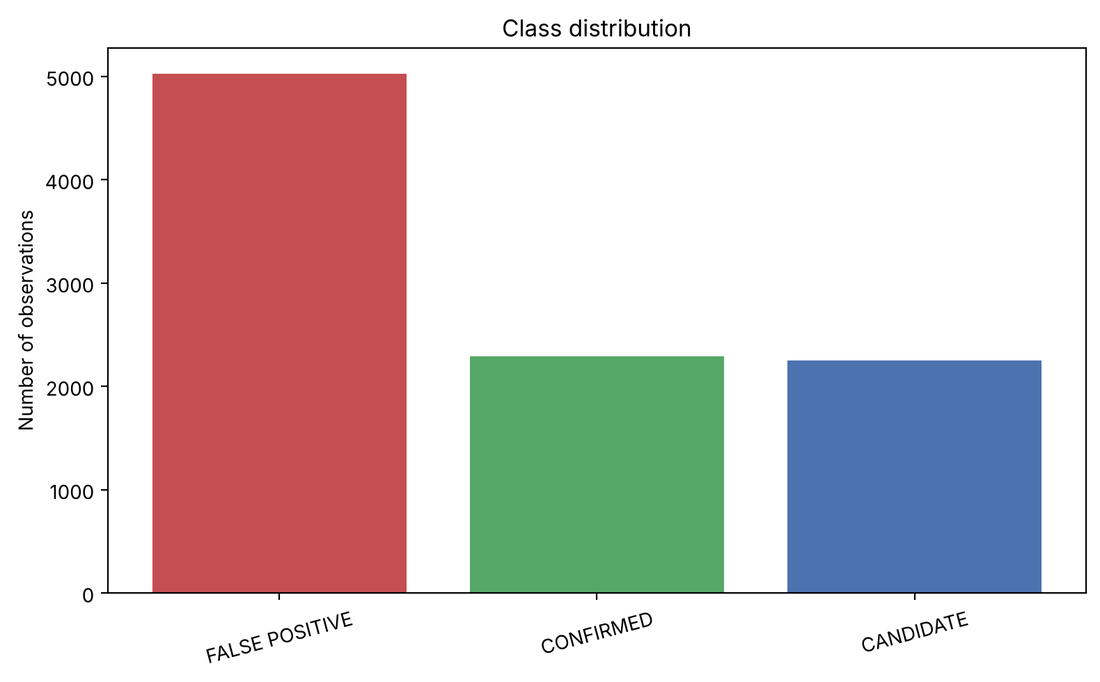

In [6]:
class_counts = df["koi_disposition"].value_counts()
percentages = class_counts / len(df) * 100

for label in class_counts.index:
    print(f"{label:15s} {class_counts[label]:5d}  ({percentages[label]:.1f}%)")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(class_counts.index, class_counts.values,
       color=["#c44e52", "#55a868", "#4c72b0"])
ax.set_ylabel("Number of observations")
ax.set_title("Class distribution")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Histograms of the physical properties

I picked four columns with a clear physical meaning: the orbital period, the
transit depth (how much the star's brightness drops), the estimated planet
radius, and the signal-to-noise ratio. I overlay the three classes in each
histogram to see which property separates them best.

I use a log scale on the x axis because these quantities span several orders of
magnitude — there are periods of hours and periods of hundreds of days.

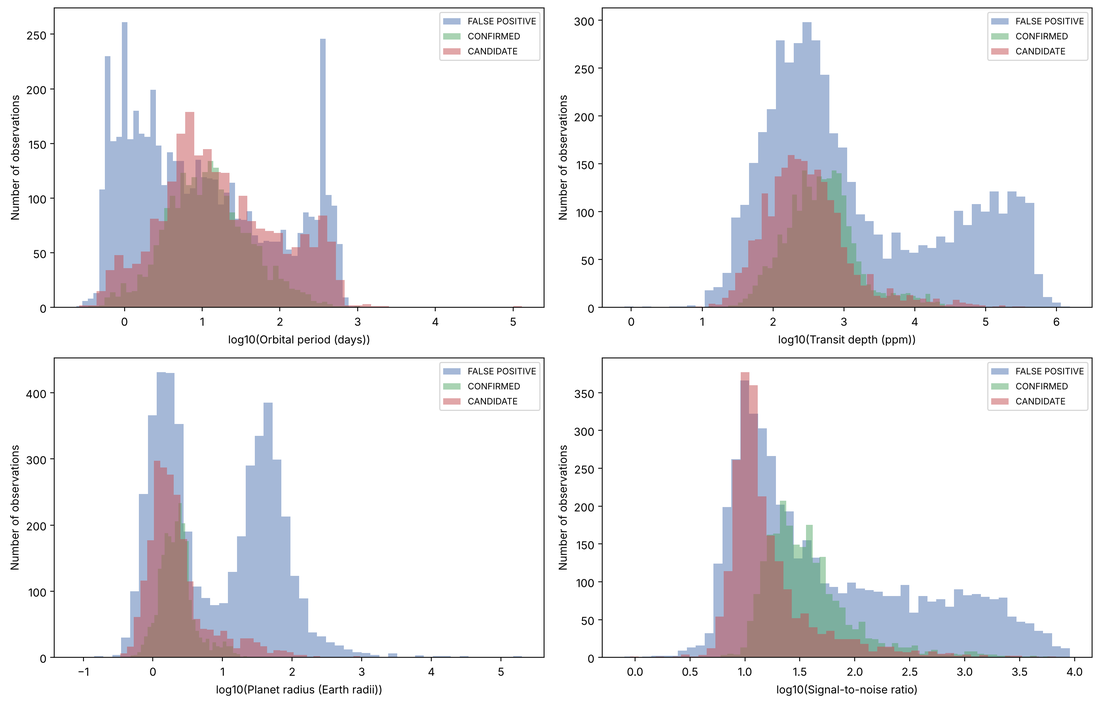

In [7]:
features = ["koi_period", "koi_depth", "koi_prad", "koi_model_snr"]
names = ["Orbital period (days)", "Transit depth (ppm)",
         "Planet radius (Earth radii)", "Signal-to-noise ratio"]
colors = {"FALSE POSITIVE": "#4c72b0", "CONFIRMED": "#55a868", "CANDIDATE": "#c44e52"}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for i in range(len(features)):
    column = features[i]
    ax = axes[i // 2][i % 2]

    for label in colors:
        values = df[df["koi_disposition"] == label][column].dropna()
        values = values[values > 0]
        ax.hist(np.log10(values), bins=50, alpha=0.5,
                label=label, color=colors[label])

    ax.set_xlabel("log10(" + names[i] + ")")
    ax.set_ylabel("Number of observations")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

The **signal-to-noise ratio** separates the classes best: false positives pile
up at low values. That makes physical sense — a weak, noisy signal is exactly
what ends up being rejected. I will keep this in mind and check it against what
SHAP says in Phase 5.

### Correlation matrix

This is to find redundant columns. Two columns with a correlation close to 1 or
to −1 are telling me the same thing, and keeping both only adds noise.

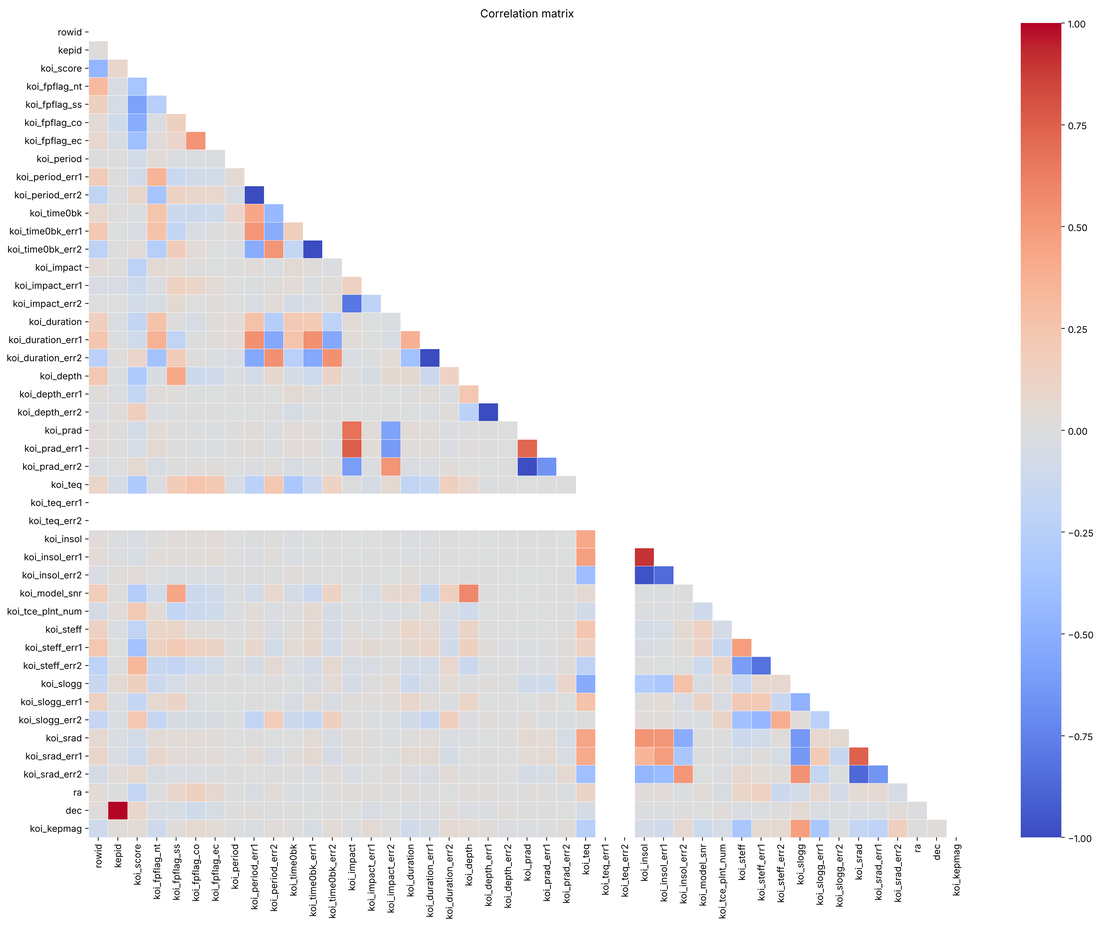

In [8]:
numeric_df = df.select_dtypes(include=[np.number])
correlations = numeric_df.corr()

mask = np.triu(np.ones_like(correlations, dtype=bool))

fig, ax = plt.subplots(figsize=(18, 14))
sns.heatmap(correlations, mask=mask, annot=False, cmap="coolwarm",
            vmin=-1, vmax=1, linewidths=0.3, ax=ax)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

In [9]:
# The _err1 and _err2 columns are the upper and lower error bars of the same
# measurement. Let me check how redundant they are before dropping the _err2 set.
print("Correlation koi_period_err1 vs koi_period_err2:",
      round(df["koi_period_err1"].corr(df["koi_period_err2"]), 4))
print("Correlation koi_prad_err1 vs koi_prad_err2:  ",
      round(df["koi_prad_err1"].corr(df["koi_prad_err2"]), 4))

Correlation koi_period_err1 vs koi_period_err2: -1.0
Correlation koi_prad_err1 vs koi_prad_err2:   -0.6607


Worth being precise here. For the orbital period the correlation is exactly
**−1**: the two columns are symmetric, one is the negative of the other. For the
planet radius it is **−0.66**, so they are not a perfect mirror.

I drop the `_err2` columns anyway, because they are still the lower error bar of
the same measurement the `_err1` column refers to. The information is largely
duplicated, and one of the two is enough for the model to know how precise that
measurement was.

## Phase 3 — Prepare the data

Three steps: drop the columns that do not help, fill in the missing values, and
put every column on the same scale.

### Step 1 — dropping columns

I drop four groups of columns, for different reasons:

1. **Identifiers and text** (`rowid`, `kepid`, `kepoi_name`, ...) — labels with
   no physical meaning. I include `koi_pdisposition` here, which is another
   version of the answer.
2. **The `_err2` columns** — the lower error bar of the same measurement as the
   `_err1` columns, as I checked above.
3. **Empty columns** (`koi_teq_err1`, `koi_teq_err2`) — zero values.
4. **Columns that give away the answer** — explained below. This is the most
   important point in the whole project.

On group 4: the `koi_score` column and the four `koi_fpflag_*` flags are not
telescope measurements. They are **the output of NASA's own vetting process** —
`koi_score` is the confidence NASA itself assigned to the classification, and the
`koi_fpflag_*` flags record the reasons an observation was marked as a false
positive.

If I left them in the training set, the model would not learn to recognise a
planet: it would learn to copy a decision that had already been made. This is
**data leakage**. In the first version of this project those columns were
included and accuracy was 90.96%. Without them it is 79.30%. The second number
is the one that measures what I actually wanted to measure.

In [10]:
id_columns = ["rowid", "kepid", "kepoi_name", "kepler_name",
              "koi_tce_delivname", "koi_pdisposition"]

err2_columns = []
for column in df.columns:
    if column.endswith("_err2"):
        err2_columns.append(column)

empty_columns = ["koi_teq_err1", "koi_teq_err2"]

# koi_score and the koi_fpflag_* flags are outputs of Kepler's vetting process:
# using them for training would be handing the model the answer.
leakage_columns = ["koi_score", "koi_fpflag_nt", "koi_fpflag_ss",
                   "koi_fpflag_co", "koi_fpflag_ec"]

# koi_teq_err2 appears both in the empty columns and in the _err2 columns, so I
# build the final list without duplicates.
columns_to_drop = []
for group in [id_columns, err2_columns, empty_columns, leakage_columns]:
    for column in group:
        if column not in columns_to_drop:
            columns_to_drop.append(column)

df_clean = df.drop(columns=columns_to_drop)

print(f"Columns before:  {df.shape[1]}")
print(f"Columns after:   {df_clean.shape[1]}")
print(f"Columns dropped: {len(columns_to_drop)}")
print(f"\nRemaining columns:\n{list(df_clean.columns)}")

Columns before:  50
Columns after:   27
Columns dropped: 23

Remaining columns:
['koi_disposition', 'koi_period', 'koi_period_err1', 'koi_time0bk', 'koi_time0bk_err1', 'koi_impact', 'koi_impact_err1', 'koi_duration', 'koi_duration_err1', 'koi_depth', 'koi_depth_err1', 'koi_prad', 'koi_prad_err1', 'koi_teq', 'koi_insol', 'koi_insol_err1', 'koi_model_snr', 'koi_tce_plnt_num', 'koi_steff', 'koi_steff_err1', 'koi_slogg', 'koi_slogg_err1', 'koi_srad', 'koi_srad_err1', 'ra', 'dec', 'koi_kepmag']


### Step 2 — missing values

Let me see where values are missing, and how many.

In [11]:
missing = df_clean.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("=== Columns with missing values ===")
print(missing)
print(f"\nTotal rows: {len(df_clean)}")

=== Columns with missing values ===
koi_slogg_err1       468
koi_srad_err1        468
koi_steff_err1       468
koi_time0bk_err1     454
koi_period_err1      454
koi_impact_err1      454
koi_duration_err1    454
koi_depth_err1       454
koi_impact           363
koi_teq              363
koi_depth            363
koi_prad             363
koi_prad_err1        363
koi_srad             363
koi_slogg            363
koi_model_snr        363
koi_steff            363
koi_tce_plnt_num     346
koi_insol            321
koi_insol_err1       321
koi_kepmag             1
dtype: int64

Total rows: 9564


Two options: drop the rows with missing values, or fill them in.

Dropping would cost me at least 468 observations, and I only have 9,564. I fill
them with the **median** of each column rather than the mean, because these
columns have strong outliers (there are orbital periods of tens of thousands of
days). The mean would be dragged by those extreme values; the median is not.

In [12]:
for column in df_clean.columns:
    if df_clean[column].isnull().sum() > 0:
        median = df_clean[column].median()
        df_clean[column] = df_clean[column].fillna(median)

print(f"Missing values after cleaning: {df_clean.isnull().sum().sum()}")
print(f"Clean dataset shape: {df_clean.shape}")

Missing values after cleaning: 0
Clean dataset shape: (9564, 27)


### Step 3 — scaling

I split the features (X) from the target (y) and put every column in the [0, 1]
range with MinMaxScaler.

For a Random Forest this is not strictly necessary — trees split on thresholds
and do not care about scale. I do it because I want to compare SHAP values across
columns without a column measured in thousands of ppm looking more important than
one measured in single units.

In [13]:
from sklearn.preprocessing import MinMaxScaler

X = df_clean.drop(columns=["koi_disposition"])
y = df_clean["koi_disposition"]

scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

print("=== Before scaling ===")
print(X[["koi_period", "koi_impact", "koi_depth"]].describe().round(2))

print("\n=== After scaling ===")
print(X_scaled[["koi_period", "koi_impact", "koi_depth"]].describe().round(2))

=== Before scaling ===


       koi_period  koi_impact   koi_depth
count     9564.00     9564.00     9564.00
mean        75.67        0.73    22904.32
std       1334.74        3.28    80790.20
min          0.24        0.00        0.00
25%          2.73        0.21      166.80
50%          9.75        0.54      421.10
75%         40.72        0.88     1341.78
max     129995.78      100.81  1541400.00

=== After scaling ===
       koi_period  koi_impact  koi_depth
count     9564.00     9564.00    9564.00
mean         0.00        0.01       0.01
std          0.01        0.03       0.05
min          0.00        0.00       0.00
25%          0.00        0.00       0.00
50%          0.00        0.01       0.00
75%          0.00        0.01       0.00
max          1.00        1.00       1.00


## Phase 4 — Train and evaluate

### Train/test split

80% for training, 20% for testing. Two details:

- `stratify=y` keeps the proportion of the three classes in both sets. Without
  it, the test set could end up with few candidates and the metrics for that
  class would stop being reliable.
- `random_state=42` fixes the split so the results are reproducible.

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y)

print(f"Training set: {X_train.shape}")
print(f"Test set:     {X_test.shape}")
print(f"\nTraining distribution:\n{y_train.value_counts()}")
print(f"\nTest distribution:\n{y_test.value_counts()}")

Training set: (7651, 26)
Test set:     (1913, 26)

Training distribution:
koi_disposition
FALSE POSITIVE    4018
CONFIRMED         1834
CANDIDATE         1799
Name: count, dtype: int64

Test distribution:
koi_disposition
FALSE POSITIVE    1005
CONFIRMED          459
CANDIDATE          449
Name: count, dtype: int64


### Random Forest

I chose a Random Forest for three reasons: it handles columns on very different
scales, it is robust to outliers (and this dataset has plenty), and it lets me
extract per-feature importance, which is what Phase 5 needs.

500 trees. I also tried fewer; above a few hundred the result barely moves and it
only gets slower.

In [15]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=500, random_state=42, n_jobs=-1)

print("Training the model...")
model.fit(X_train, y_train)

print("Model trained.")
print(f"Number of trees:    {model.n_estimators}")
print(f"Number of features: {model.n_features_in_}")

Training the model...


Model trained.
Number of trees:    500
Number of features: 26


### Evaluation

Accuracy is only the first number. What I care about is **recall per class**: of
all the confirmed planets in the test set, how many did the model actually find?

In [16]:
from sklearn.metrics import classification_report, accuracy_score

y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}\n")
print("=== Classification report ===")
print(classification_report(y_test, y_pred))

Accuracy: 79.30%

=== Classification report ===
                precision    recall  f1-score   support

     CANDIDATE       0.66      0.46      0.54       449
     CONFIRMED       0.81      0.85      0.83       459
FALSE POSITIVE       0.83      0.92      0.87      1005

      accuracy                           0.79      1913
     macro avg       0.76      0.74      0.75      1913
  weighted avg       0.78      0.79      0.78      1913



Reading these numbers:

- **FALSE POSITIVE** — recall 0.92. The majority class, and the one with the most
  distinctive patterns.
- **CONFIRMED** — recall 0.85. The model finds 85% of the confirmed planets.
- **CANDIDATE** — recall 0.46. It finds fewer than half. This is not an accident:
  a candidate is by definition an observation whose evidence was inconclusive,
  with properties that overlap those of the other two classes.

Against the baseline from Phase 2 (always answering "FALSE POSITIVE" would give
52.5%), the 79.30% shows the model learned something real.

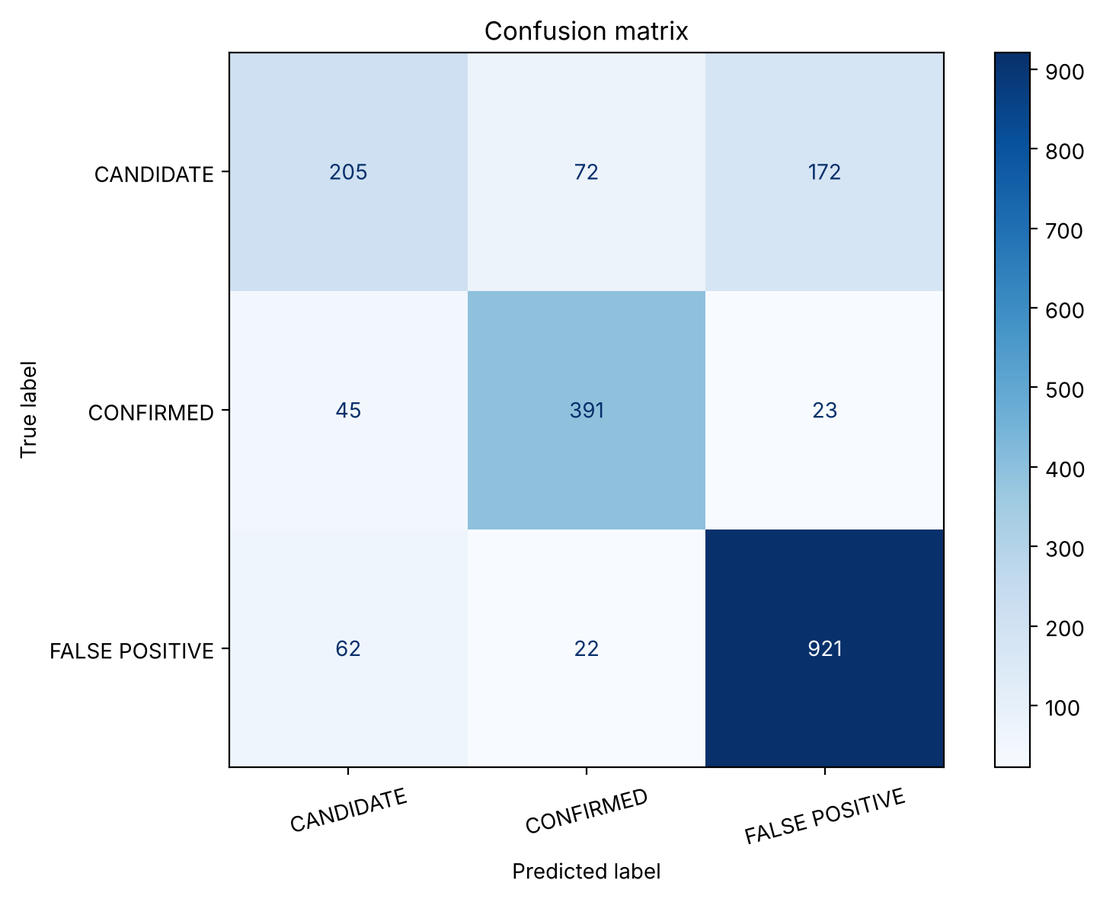

[[205  72 172]
 [ 45 391  23]
 [ 62  22 921]]


In [17]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

labels = ["CANDIDATE", "CONFIRMED", "FALSE POSITIVE"]
cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(8, 6))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
display.plot(ax=ax, colorbar=True, cmap="Blues")
ax.set_title("Confusion matrix")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

print(cm)

The most frequent error is classifying candidates as false positives (172 cases).
When the evidence is weak, the model leans towards the majority class.

The second most frequent error — 72 candidates classified as confirmed — is the
more interesting one: these are candidates whose properties look like those of
already-confirmed planets, which is exactly the set worth prioritising for
follow-up observation.

## Phase 5 — Explaining the decisions with SHAP

Getting 79% right does not tell me *what* the model is basing its decisions on.
SHAP assigns each feature a value measuring how much it pushed a given
prediction up or down, for one specific observation.

I use `TreeExplainer`, the version optimised for tree-based models.

In [18]:
import shap

explainer = shap.TreeExplainer(model)

print("Computing SHAP values...")
shap_values = explainer.shap_values(X_test)

print("Done.")
print(f"SHAP values shape: {shap_values.shape}")

Computing SHAP values...


Done.
SHAP values shape: (1913, 26, 3)


The result has shape `(1913, 26, 3)`: for each of the 1,913 test observations,
for each of the 26 features, one contribution towards each of the 3 classes. I
take the CONFIRMED class, because the question I care about is what makes the
model decide there is a real planet there.

Class order: ['CANDIDATE', 'CONFIRMED', 'FALSE POSITIVE']


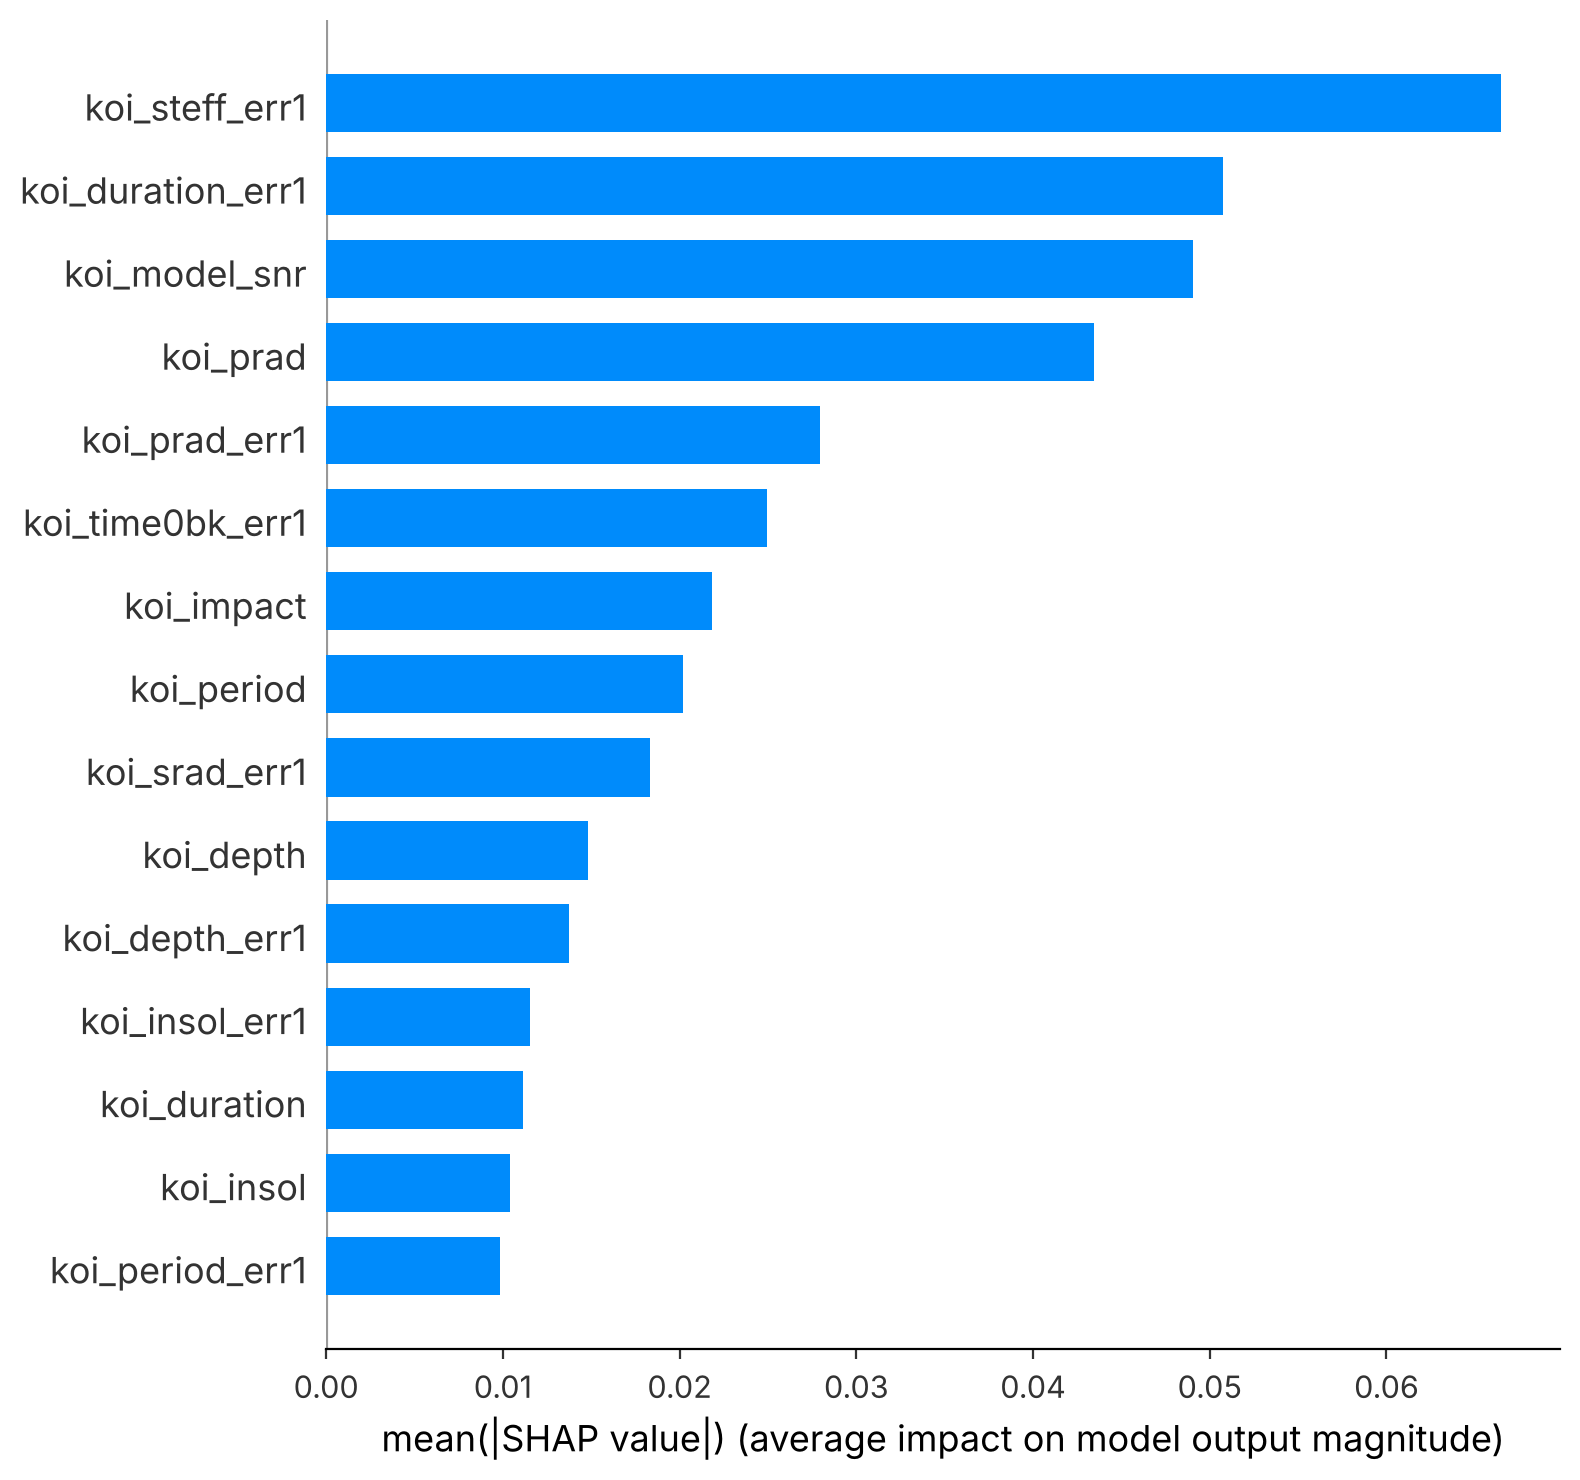

In [19]:
classes = list(model.classes_)
print(f"Class order: {classes}")

confirmed_index = classes.index("CONFIRMED")
shap_confirmed = shap_values[:, :, confirmed_index]

shap.summary_plot(shap_confirmed, X_test, plot_type="bar",
                  max_display=15, show=True)

The three most influential features are `koi_steff_err1`, `koi_duration_err1`
and `koi_model_snr`.

This deserves an honest note. I expected signal-to-noise first, as the
histograms in Phase 2 suggested — it does show up, but third. The top two are
**measurement uncertainties**: the error on the star's effective temperature and
the error on the transit duration. So part of what the model learned is not
planet physics, it is **how well each observation was measured**. Poorly measured
observations tend to end up classified a certain way, and the model picked up on
that.

This is a real limitation of the project, and it is the kind of thing only an
explainability tool surfaces.

### Local explanation — a single star

The previous plot is an average over the 1,913 test observations. Now I take one
specific star and look at how that individual decision was built up.

Chosen star index: 7
True class:      CONFIRMED
Predicted class: CONFIRMED


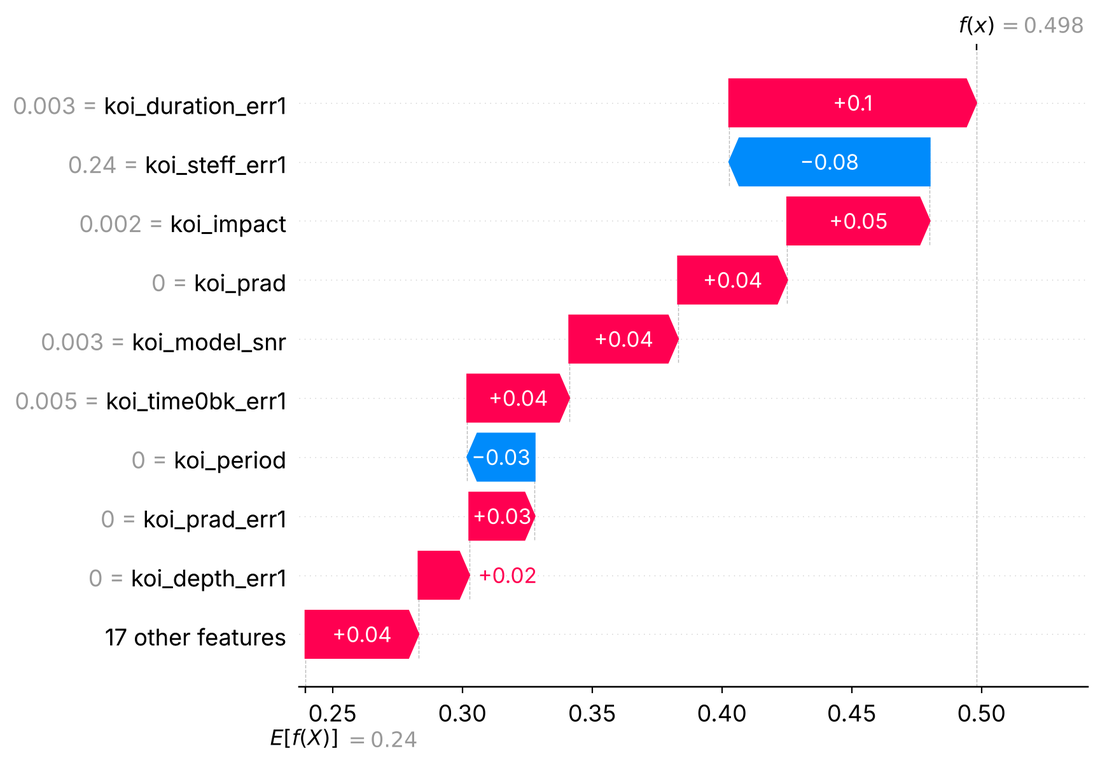

In [20]:
confirmed_rows = []
for i in range(len(y_pred)):
    if y_pred[i] == "CONFIRMED":
        confirmed_rows.append(i)

star_index = confirmed_rows[0]

print(f"Chosen star index: {star_index}")
print(f"True class:      {y_test.iloc[star_index]}")
print(f"Predicted class: {y_pred[star_index]}")

star_shap = shap_values[star_index, :, confirmed_index]

shap.waterfall_plot(
    shap.Explanation(
        values=star_shap,
        base_values=explainer.expected_value[confirmed_index],
        data=X_test.iloc[star_index],
        feature_names=list(X_test.columns)))

This star was classified as CONFIRMED with probability 0.498, starting from a
base value of 0.24. It was the most likely of the three classes, but not by a
wide margin.

`koi_duration_err1` pushed +0.10 and `koi_impact` +0.05, while `koi_steff_err1`
(−0.08) and `koi_period` (−0.03) pushed the other way. No single feature decides
on its own: the classification comes out of many small contributions adding up.

This is also where the value of removing `koi_score` shows. In the first version
of the project this same plot was dominated by one single bar — `koi_score` — and
that was the signal that something was wrong.

## Conclusions

| | Accuracy | Recall CANDIDATE | Recall CONFIRMED | Recall FALSE POSITIVE |
|---|---|---|---|---|
| With `koi_score` and `koi_fpflag_*` | 90.96% | 0.80 | 0.85 | 0.99 |
| Without them (final version) | 79.30% | 0.46 | 0.85 | 0.92 |

1. **The data leakage was worth 11 accuracy points.** This was the most useful
   part of the project: the higher number was the wrong number.
2. **Candidates are the hard class** (recall 0.46), and that reflects what the
   class is.
3. **Signal-to-noise matters but is not the main driver.** The two most
   influential features are measurement uncertainties, which is a limitation to
   state rather than hide.

What I would do next: train the model using only the physical measurement
columns, leaving out every `_err1` column, to measure how much of the result
depends on measurement quality rather than on the signal itself.